## 📦 Step 1 — Install & Import Libraries

In [ ]:
# Install required libraries (run once)
!pip install pandas numpy matplotlib seaborn scikit-learn joblib flask flask-cors imbalanced-learn

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, classification_report,
                              confusion_matrix, roc_auc_score, roc_curve)
from sklearn.impute import SimpleImputer
import joblib

# Plot style
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette('coolwarm')
print('✅ All libraries imported successfully!')

✅ All libraries imported successfully!


## 📂 Step 2 — Load Dataset


In [ ]:
# Load the dataset
df = pd.read_csv('/content/drive/MyDrive/splproject/kidney_disease.csv')

print('📊 Dataset Shape:', df.shape)
print('\n🔍 First 5 rows:')
df.head()

📊 Dataset Shape: (400, 26)

🔍 First 5 rows:


,id,age,bp,sg,al,su,rbc,pc,pcc,ba,...,pcv,wc,rc,htn,dm,cad,appet,pe,ane,classification
0,0,48.0,80.0,1.020,1.0,0.0,NaN,normal,notpresent,notpresent,...,44,7800,5.2,yes,yes,no,good,no,no,ckd
1,1,7.0,50.0,1.020,4.0,0.0,NaN,normal,notpresent,notpresent,...,38,6000,NaN,no,no,no,good,no,no,ckd
2,2,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,...,31,7500,NaN,no,yes,no,poor,no,yes,ckd
3,3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,...,32,6700,3.9,yes,no,no,poor,yes,yes,ckd
4,4,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,...,35,7300,4.6,no,no,no,good,no,no,ckd


In [ ]:
!ls /content/drive/MyDrive/splproject/

kidney_disease.csv


### Method 1: Using the Colab File Browser

This is the simplest way for a single file:

1.  On the left sidebar of your Colab notebook, click the **'Files' icon** (looks like a folder).
2.  Click the **'Upload to session storage' icon** (looks like an arrow pointing up into a cloud).
3.  Browse your local machine and select your `kidney_disease.csv` file.

**Note**: Files uploaded this way are temporary and will be deleted when your Colab runtime disconnects.

### Method 2: Mounting Google Drive (Recommended for persistent storage)

This method connects your Google Drive to Colab, allowing you to access files stored there persistently.

1.  Run the following code cell to mount your Google Drive:

    ```python
    from google.colab import drive
    drive.mount('/content/drive')
    ```

2.  Follow the instructions in the output to authenticate your Google Drive account.
3.  Once mounted, you can place your `kidney_disease.csv` file in your Google Drive (e.g., in a folder named `Colab Notebooks` or a specific project folder).
4.  You can then access the file using its path, for example: `'/content/drive/MyDrive/path/to/your/kidney_disease.csv'` (replace `path/to/your` with the actual path in your Drive).

This method ensures your files remain accessible across different Colab sessions.

In [ ]:
# After uploading or mounting, you can verify the file is there.
# For Method 1 (file browser upload) or if kidney_disease.csv is in the current directory:
# !ls

# For Method 2 (Google Drive mount), assuming it's in the root of MyDrive for testing:
!ls /content/drive/MyDrive/

# Or, if you know the exact path:
# !ls /content/drive/MyDrive/your_folder/kidney_disease.csv

# Then you can load it using the correct path:
# df = pd.read_csv('kidney_disease.csv') # For Method 1
# df = pd.read_csv('/content/drive/MyDrive/path/to/your/kidney_disease.csv') # For Method 2

'~$module2.ppt.gdoc'
'23STUCHH010843 (1).pdf'
 23STUCHH010843.pdf
'23STUCHH010843_Saladi Vanshika.gdoc'
'23STUCHH010843_Saladi Vanshika.pdf'
'Aayu(1).pptx'
'Aayu _ Smart Health Platform - Personal - Microsoft​ Edge 2025-10-31 23-54-51.mp4'
'AI_ASSIGNMENT-1(23STUCHH010843).gdoc'
 AI_Skills_Passport_SaladiVanshika.pdf
 Assignment.gdoc
'ATTENDANCE LETTER.gdoc'
'AWS CERTIFICATE.pdf'
'Book report.gdoc'
'CHAPTER 1 - MULTI DISCIPLINARY NATURE OF ENVIRONMENT.gdoc'
'CHAPTER 2 - RENEWABLE AND NON-RENEWABLE SOURCES.gdoc'
'CHAPTER 3 - WATER RESOURCES.gdoc'
'CHAPTER 4 - ENERGY RESOURCES.gdoc'
 Classroom
'Colab Notebooks'
'Completion Certificate _ SkillsBuild.pdf'
 Document.docx
 Document.pdf
'DSC REPORT.docx'
 F_843.pdf
 IBMDesign20251023-32-fwcftu.pdf
 kidney_disease.csv
'LAB-01(08-01-2026).gdoc'
'LAB-02(29-01-2026).gdoc'
'LAB-06(26-02-2026).gdoc'
'leetcode solutions.gdoc'
 ML_CASESTUDY.docx
 ML_CASE_STUDY.pdf
'ML_CASE_STUDY_PRESENTATION (1).pptx'
'PC REPORT TEMPLATE.docx'
'poc vans.gdoc'
'pointer

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:

import pandas as pd

df = pd.read_csv('/content/drive/MyDrive/splproject/kidney_disease.csv')
df.head()

,id,age,bp,sg,al,su,rbc,pc,pcc,ba,...,pcv,wc,rc,htn,dm,cad,appet,pe,ane,classification
0,0,48.0,80.0,1.020,1.0,0.0,NaN,normal,notpresent,notpresent,...,44,7800,5.2,yes,yes,no,good,no,no,ckd
1,1,7.0,50.0,1.020,4.0,0.0,NaN,normal,notpresent,notpresent,...,38,6000,NaN,no,no,no,good,no,no,ckd
2,2,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,...,31,7500,NaN,no,yes,no,poor,no,yes,ckd
3,3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,...,32,6700,3.9,yes,no,no,poor,yes,yes,ckd
4,4,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,...,35,7300,4.6,no,no,no,good,no,no,ckd


In [ ]:
# Load the dataset
df = pd.read_csv('/content/drive/MyDrive/splproject/kidney_disease.csv')

print('📊 Dataset Shape:', df.shape)
print('\n🔍 First 5 rows:')
df.head()

📊 Dataset Shape: (400, 26)

🔍 First 5 rows:


,id,age,bp,sg,al,su,rbc,pc,pcc,ba,...,pcv,wc,rc,htn,dm,cad,appet,pe,ane,classification
0,0,48.0,80.0,1.020,1.0,0.0,NaN,normal,notpresent,notpresent,...,44,7800,5.2,yes,yes,no,good,no,no,ckd
1,1,7.0,50.0,1.020,4.0,0.0,NaN,normal,notpresent,notpresent,...,38,6000,NaN,no,no,no,good,no,no,ckd
2,2,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,...,31,7500,NaN,no,yes,no,poor,no,yes,ckd
3,3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,...,32,6700,3.9,yes,no,no,poor,yes,yes,ckd
4,4,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,...,35,7300,4.6,no,no,no,good,no,no,ckd


In [ ]:
print('📋 Dataset Info:')
print(df.info())
print('\n📈 Basic Statistics:')
df.describe()

📋 Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 26 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   id              400 non-null    int64  
 1   age             391 non-null    float64
 2   bp              388 non-null    float64
 3   sg              353 non-null    float64
 4   al              354 non-null    float64
 5   su              351 non-null    float64
 6   rbc             248 non-null    object 
 7   pc              335 non-null    object 
 8   pcc             396 non-null    object 
 9   ba              396 non-null    object 
 10  bgr             356 non-null    float64
 11  bu              381 non-null    float64
 12  sc              383 non-null    float64
 13  sod             313 non-null    float64
 14  pot             312 non-null    float64
 15  hemo            348 non-null    float64
 16  pcv             330 non-null    object 
 17  wc              295

,id,age,bp,sg,al,su,bgr,bu,sc,sod,pot,hemo
count,400.000000,391.000000,388.000000,353.000000,354.000000,351.000000,356.000000,381.000000,383.000000,313.000000,312.000000,348.000000
mean,199.500000,51.483376,76.469072,1.017408,1.016949,0.450142,148.036517,57.425722,3.072454,137.528754,4.627244,12.526437
std,115.614301,17.169714,13.683637,0.005717,1.352679,1.099191,79.281714,50.503006,5.741126,10.408752,3.193904,2.912587
min,0.000000,2.000000,50.000000,1.005000,0.000000,0.000000,22.000000,1.500000,0.400000,4.500000,2.500000,3.100000
25%,99.750000,42.000000,70.000000,1.010000,0.000000,0.000000,99.000000,27.000000,0.900000,135.000000,3.800000,10.300000
50%,199.500000,55.000000,80.000000,1.020000,0.000000,0.000000,121.000000,42.000000,1.300000,138.000000,4.400000,12.650000
75%,299.250000,64.500000,80.000000,1.020000,2.000000,0.000000,163.000000,66.000000,2.800000,142.000000,4.900000,15.000000
max,399.000000,90.000000,180.000000,1.025000,5.000000,5.000000,490.000000,391.000000,76.000000,163.000000,47.000000,17.800000


🎯 Target Variable Distribution:
classification
1    250
0    150
Name: count, dtype: int64

🎯 Target Variable Distribution (after cleaning):
classification
1    250
0    150
Name: count, dtype: int64


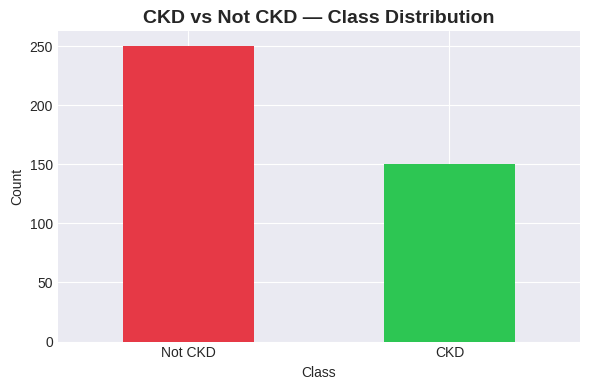

In [ ]:
print('🎯 Target Variable Distribution:')
print(df['classification'].value_counts())

# Note: The 'classification' column has already been cleaned and encoded to numeric by previous steps.
# The string cleaning code below was causing an error because the column is no longer string type.
# df['classification'] = df['classification'].str.strip().replace('ckd\t', 'ckd')

# Verify the cleaned distribution (already numeric here)
print('\n🎯 Target Variable Distribution (after cleaning):')
print(df['classification'].value_counts())

fig, ax = plt.subplots(figsize=(6,4))
df['classification'].value_counts().plot(kind='bar', color=['#e63946','#2dc653'], ax=ax)
ax.set_title('CKD vs Not CKD — Class Distribution', fontsize=14, fontweight='bold')
ax.set_xlabel('Class')
ax.set_ylabel('Count')
# Ensure labels match the actual number of unique values (0 and 1)
ax.set_xticklabels(['Not CKD', 'CKD'], rotation=0)
plt.tight_layout()
plt.show()

## 🧹 Step 3 — Data Preprocessing

In [ ]:
# Step 3.1 — Fix column names
df.columns = df.columns.str.strip()

# Drop id column if present
if 'id' in df.columns:
    df.drop('id', axis=1, inplace=True);

# Fix target column — strip whitespace and standardize
df['classification'] = df['classification'].str.strip().str.lower()
df['classification'] = df['classification'].replace({'ckd\t': 'ckd', 'notckd': 'notckd'})

print('🔤 Unique target values:', df['classification'].unique())
print('✅ Columns cleaned')

🔤 Unique target values: ['ckd' 'notckd']
✅ Columns cleaned


❗ Missing Values Summary:
       Missing Count  Missing %
rbc              152      38.00
rc               130      32.50
wc               105      26.25
pot               88      22.00
sod               87      21.75
pcv               70      17.50
pc                65      16.25
hemo              52      13.00
su                49      12.25
sg                47      11.75
al                46      11.50
bgr               44      11.00
bu                19       4.75
sc                17       4.25
bp                12       3.00
age                9       2.25
pcc                4       1.00
ba                 4       1.00
htn                2       0.50
dm                 2       0.50
cad                2       0.50
appet              1       0.25
pe                 1       0.25
ane                1       0.25


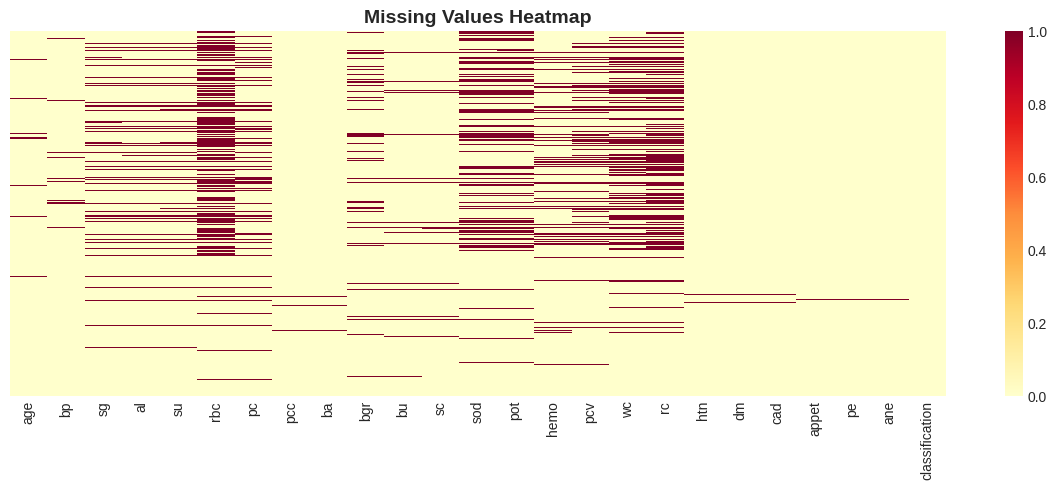

In [ ]:
# Step 3.2 — Analyze missing values
missing = df.isnull().sum()
missing_pct = (missing / len(df)) * 100
missing_df = pd.DataFrame({'Missing Count': missing, 'Missing %': missing_pct})
missing_df = missing_df[missing_df['Missing Count'] > 0].sort_values('Missing %', ascending=False)

print('❗ Missing Values Summary:')
print(missing_df)

# Visualize missing values
plt.figure(figsize=(12,5))
sns.heatmap(df.isnull(), yticklabels=False, cbar=True, cmap='YlOrRd')
plt.title('Missing Values Heatmap', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
# Step 3.3 — Separate numeric and categorical columns
# Known numeric columns
numeric_cols = ['age','bp','sg','al','su','bgr','bu','sc','sod','pot','hemo','pcv','wc','rc']
# Known categorical columns
cat_cols = ['rbc','pc','pcc','ba','htn','dm','cad','appet','pe','ane']

# Convert numeric columns (some may be stored as object due to '\t' or '?' characters)
for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce')

# Strip whitespace from categorical
for col in cat_cols:
    if col in df.columns:
        df[col] = df[col].astype(str).str.strip().str.lower()
        df[col] = df[col].replace({'nan': np.nan, '': np.nan})

print('✅ Data types fixed')
print(df.dtypes)

✅ Data types fixed
age               float64
bp                float64
sg                float64
al                float64
su                float64
rbc                object
pc                 object
pcc                object
ba                 object
bgr               float64
bu                float64
sc                float64
sod               float64
pot               float64
hemo              float64
pcv               float64
wc                float64
rc                float64
htn                object
dm                 object
cad                object
appet              object
pe                 object
ane                object
classification     object
dtype: object


In [ ]:
# Step 3.4 — Impute missing values
# Numeric → mean imputation
num_imputer = SimpleImputer(strategy='mean')
existing_numeric = [c for c in numeric_cols if c in df.columns]
df[existing_numeric] = num_imputer.fit_transform(df[existing_numeric])

# Categorical → mode imputation
cat_imputer = SimpleImputer(strategy='most_frequent')
existing_cat = [c for c in cat_cols if c in df.columns]
df[existing_cat] = cat_imputer.fit_transform(df[existing_cat])

print('✅ Missing values after imputation (total):', df.isnull().sum().sum())
print('Columns with remaining missing values:\n', df.isnull().sum()[df.isnull().sum() > 0])

✅ Missing values after imputation (total): 0
Columns with remaining missing values:
 Series([], dtype: int64)


In [ ]:
# Step 3.5 — Label Encoding for categorical columns
le = LabelEncoder()
for col in existing_cat:
    df[col] = le.fit_transform(df[col].astype(str))

# Encode target: ckd=1, notckd=0
df['classification'] = df['classification'].map({'ckd': 1, 'notckd': 0})

print('✅ Encoding complete')
print('Target value counts:')
print(df['classification'].value_counts())
df.head()

✅ Encoding complete
Target value counts:
classification
1    250
0    150
Name: count, dtype: int64


,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,...,pcv,wc,rc,htn,dm,cad,appet,pe,ane,classification
0,48.0,80.0,1.020,1.0,0.0,1,1,0,0,121.000000,...,44.0,7800.0,5.200000,1,1,0,0,0,0,1
1,7.0,50.0,1.020,4.0,0.0,1,1,0,0,148.036517,...,38.0,6000.0,4.707435,0,0,0,0,0,0,1
2,62.0,80.0,1.010,2.0,3.0,1,1,0,0,423.000000,...,31.0,7500.0,4.707435,0,1,0,1,0,1,1
3,48.0,70.0,1.005,4.0,0.0,1,0,1,0,117.000000,...,32.0,6700.0,3.900000,1,0,0,1,1,1,1
4,51.0,80.0,1.010,2.0,0.0,1,1,0,0,106.000000,...,35.0,7300.0,4.600000,0,0,0,0,0,0,1


## 📊 Step 4 — Data Visualization

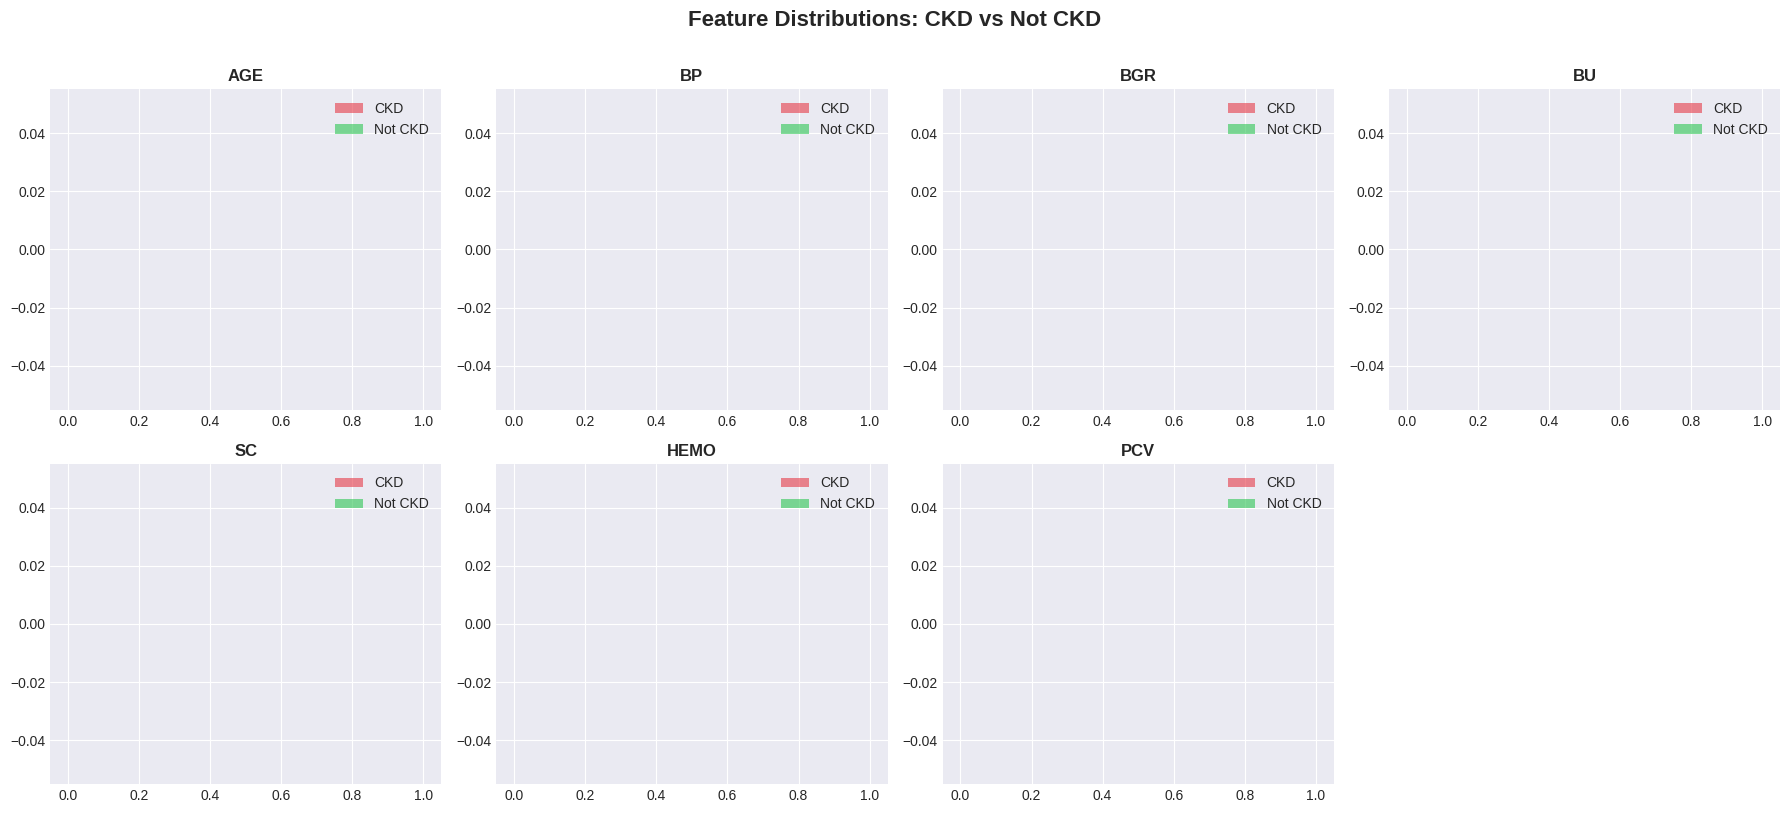

In [ ]:
# Step 4.1 — Distribution of key numeric features
key_features = ['age','bp','bgr','bu','sc','hemo','pcv']
key_features = [f for f in key_features if f in df.columns]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()

for i, col in enumerate(key_features):
    axes[i].hist(df[df['classification']==1][col], alpha=0.6, label='CKD', color='#e63946', bins=20)
    axes[i].hist(df[df['classification']==0][col], alpha=0.6, label='Not CKD', color='#2dc653', bins=20)
    axes[i].set_title(col.upper(), fontweight='bold')
    axes[i].legend()

# Hide extra axes
for j in range(len(key_features), len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Feature Distributions: CKD vs Not CKD', fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

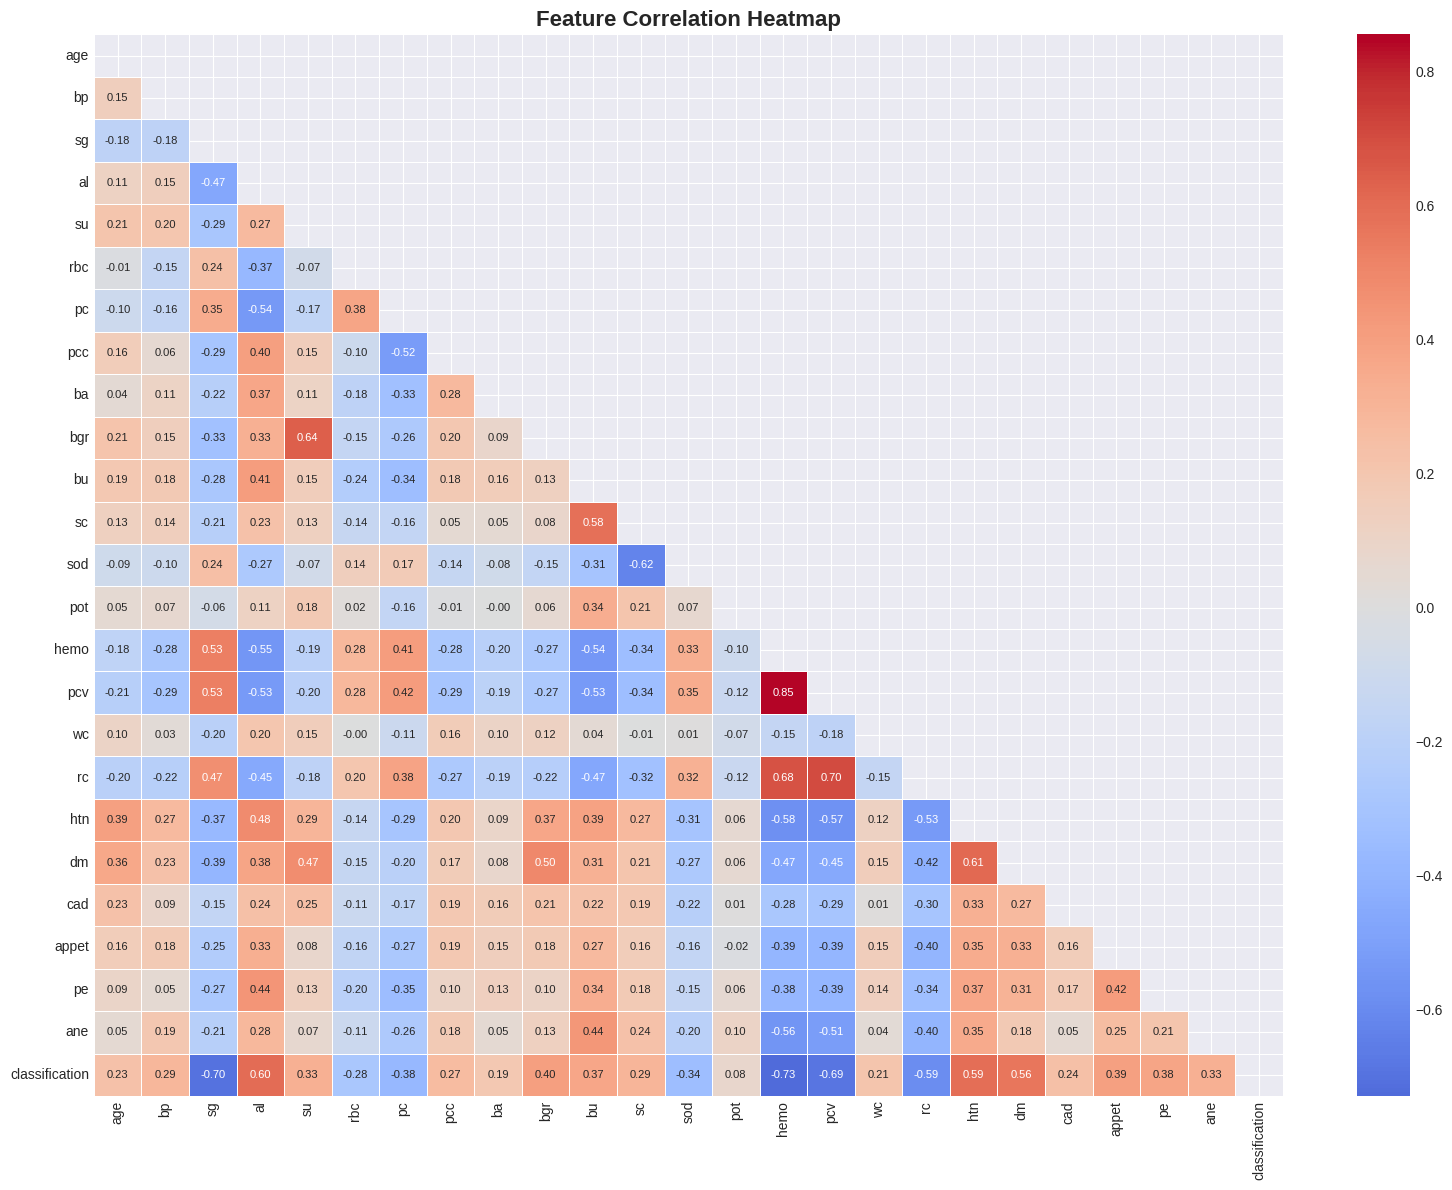

In [ ]:
# Step 4.2 — Correlation Heatmap
plt.figure(figsize=(16, 12))
corr = df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, linewidths=0.5, annot_kws={'size':8})
plt.title('Feature Correlation Heatmap', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

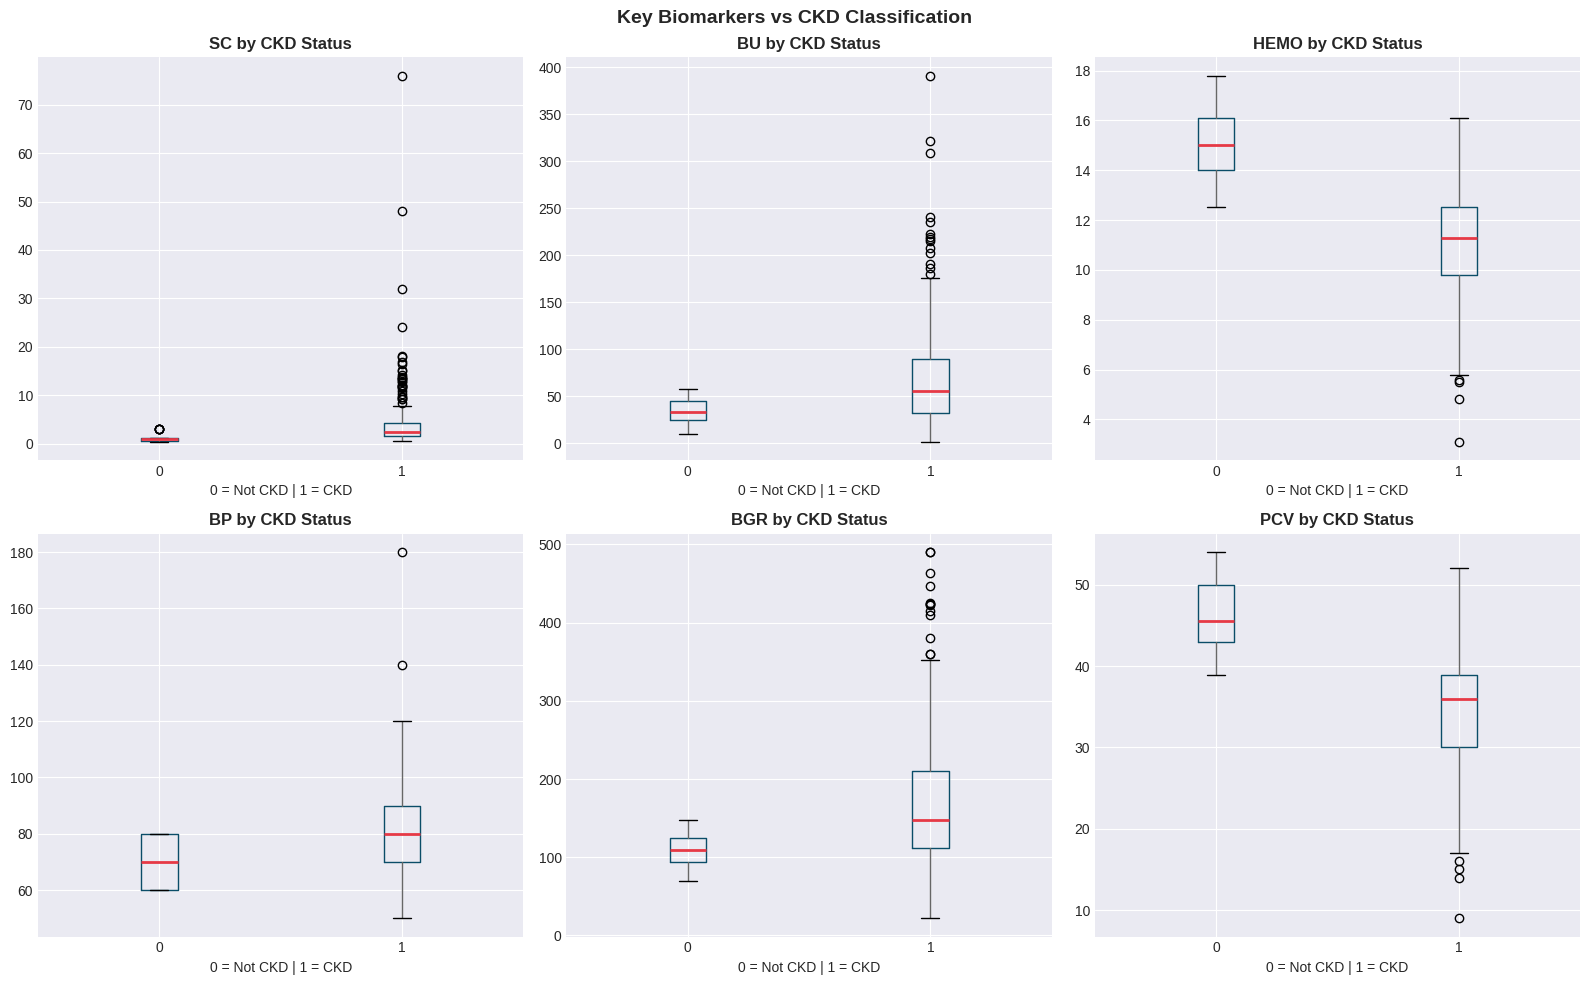

In [ ]:
# Step 4.3 — Boxplots for key features vs CKD
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()
box_features = ['sc','bu','hemo','bp','bgr','pcv']
box_features = [f for f in box_features if f in df.columns]

for i, col in enumerate(box_features[:6]):
    df.boxplot(column=col, by='classification', ax=axes[i],
               boxprops=dict(color='#0a4d68'),
               medianprops=dict(color='#e63946', linewidth=2))
    axes[i].set_title(f'{col.upper()} by CKD Status', fontweight='bold')
    axes[i].set_xlabel('0 = Not CKD | 1 = CKD')

plt.suptitle('Key Biomarkers vs CKD Classification', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

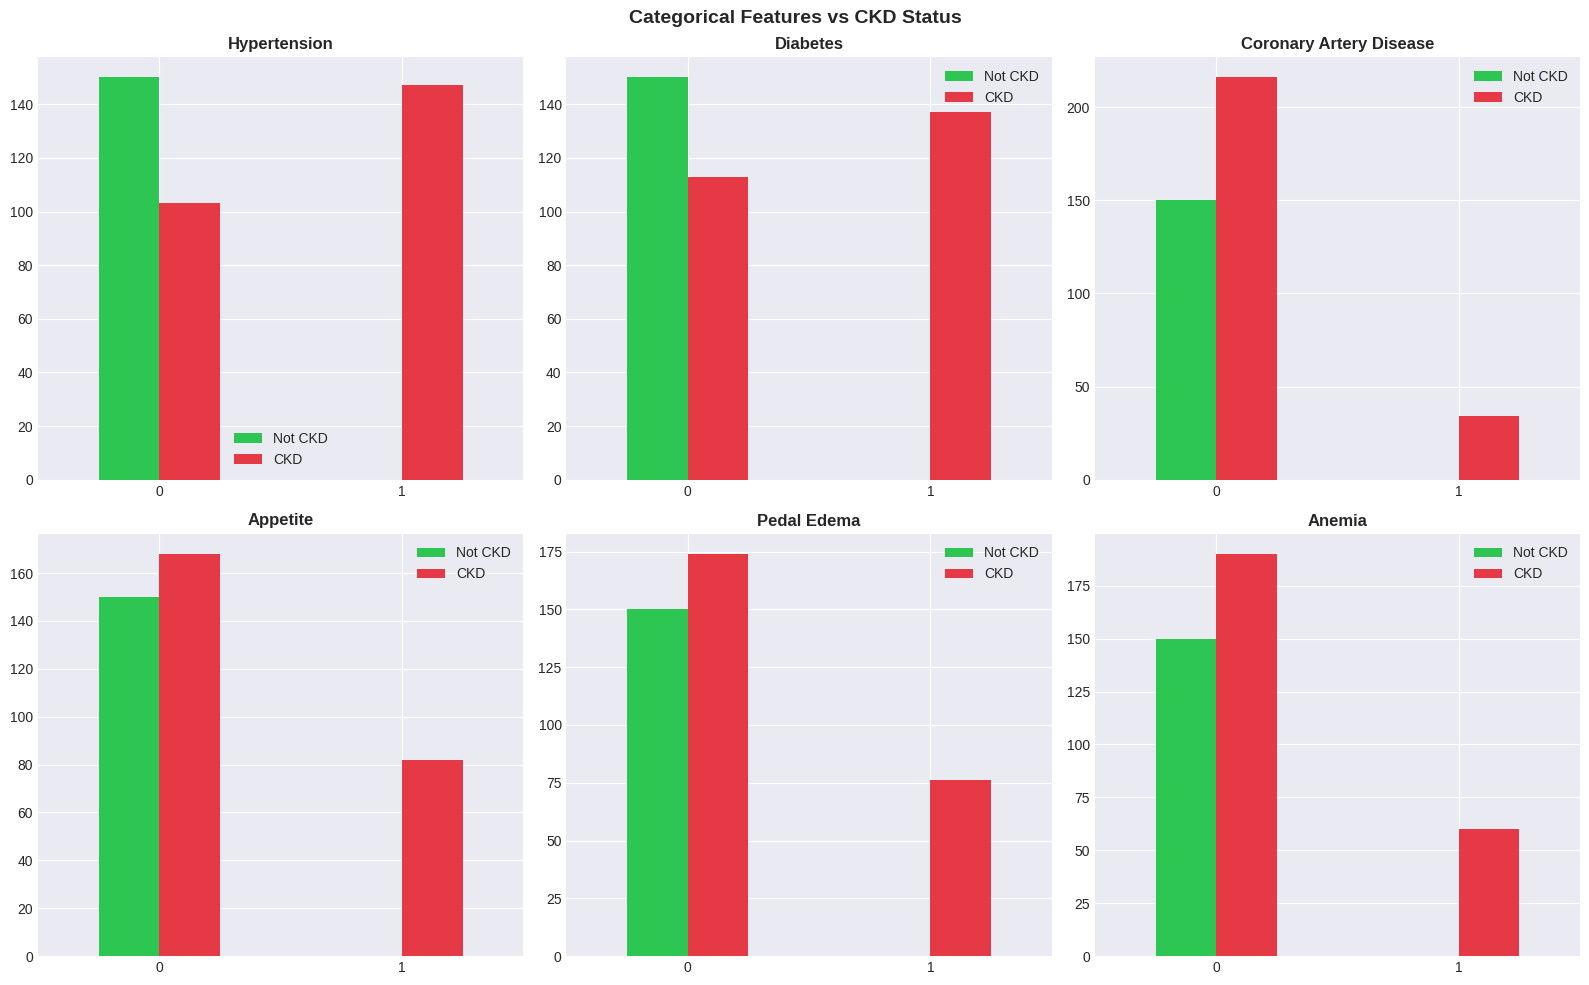

In [ ]:
# Step 4.4 — Categorical feature analysis
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()
cat_features_plot = ['htn','dm','cad','appet','pe','ane']
cat_features_plot = [f for f in cat_features_plot if f in df.columns]
labels = {'htn':'Hypertension','dm':'Diabetes','cad':'Coronary Artery Disease',
          'appet':'Appetite','pe':'Pedal Edema','ane':'Anemia'}

for i, col in enumerate(cat_features_plot[:6]):
    ct = pd.crosstab(df[col], df['classification'])
    ct.plot(kind='bar', ax=axes[i], color=['#2dc653','#e63946'])
    axes[i].set_title(labels.get(col, col), fontweight='bold')
    axes[i].set_xlabel('')
    axes[i].legend(['Not CKD', 'CKD'])
    axes[i].tick_params(axis='x', rotation=0)

plt.suptitle('Categorical Features vs CKD Status', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

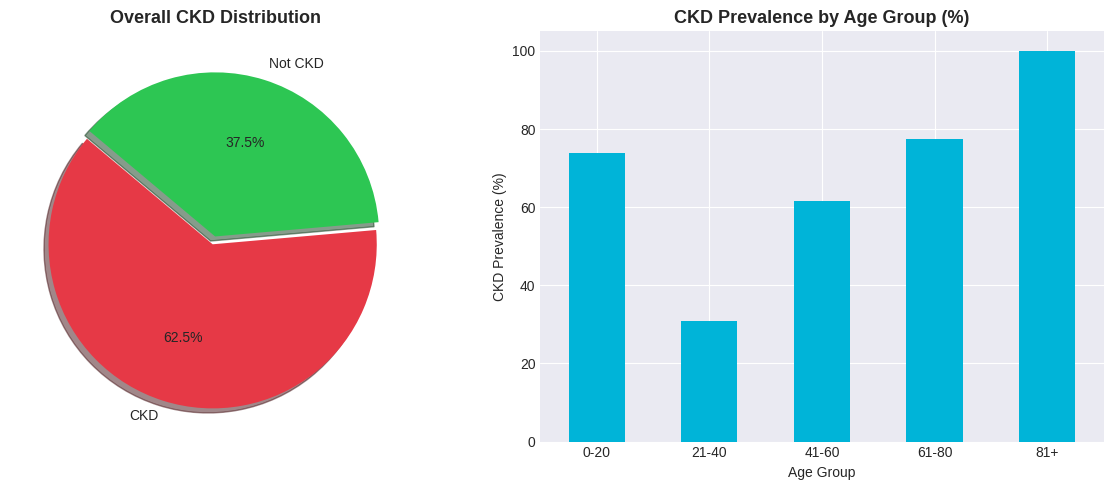

In [ ]:
# Step 4.5 — Pie chart of CKD distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Pie
counts = df['classification'].value_counts()
axes[0].pie(counts, labels=['CKD', 'Not CKD'], autopct='%1.1f%%',
            colors=['#e63946','#2dc653'], startangle=140,
            explode=(0.05, 0), shadow=True)
axes[0].set_title('Overall CKD Distribution', fontweight='bold', fontsize=13)

# Age group analysis
df['age_group'] = pd.cut(df['age'], bins=[0,20,40,60,80,100],
                          labels=['0-20','21-40','41-60','61-80','81+'])
age_ckd = df.groupby('age_group')['classification'].mean() * 100
age_ckd.plot(kind='bar', ax=axes[1], color='#00b4d8')
axes[1].set_title('CKD Prevalence by Age Group (%)', fontweight='bold', fontsize=13)
axes[1].set_xlabel('Age Group')
axes[1].set_ylabel('CKD Prevalence (%)')
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

## ✂️ Step 5 — Feature Selection & Train/Test Split

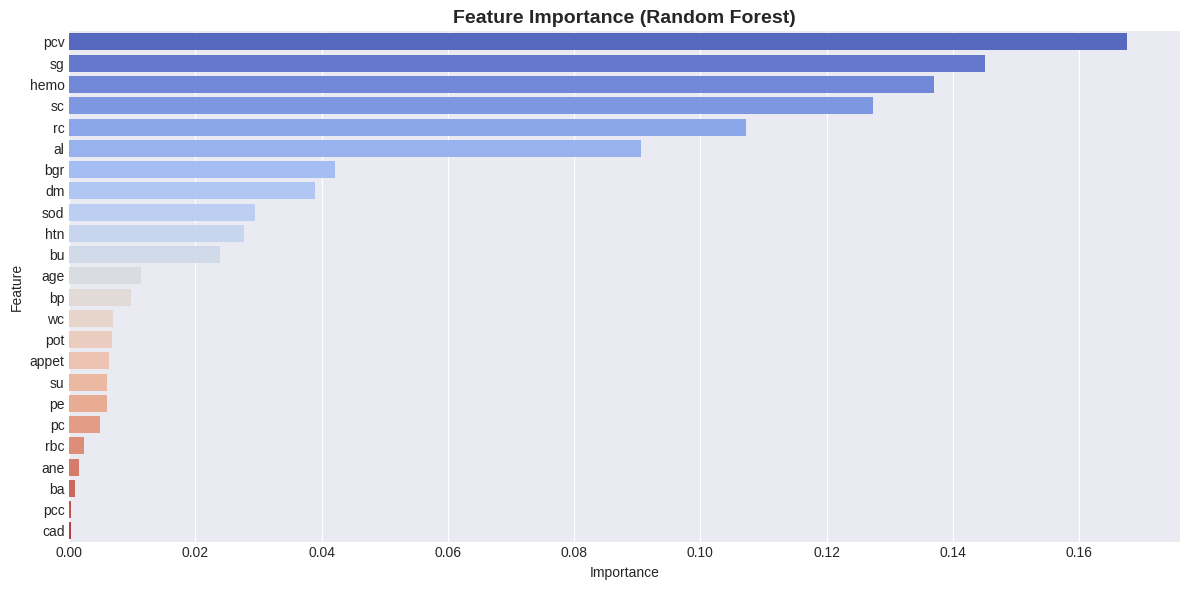

Top 10 most important features:
   Feature  Importance
15     pcv    0.167637
2       sg    0.145040
14    hemo    0.136969
11      sc    0.127377
17      rc    0.107267
3       al    0.090631
9      bgr    0.042056
19      dm    0.038917
12     sod    0.029389
18     htn    0.027703


In [ ]:
# Step 5.1 — Feature Importance using Random Forest
feature_cols = [c for c in df.columns if c not in ['classification','age_group']]
X = df[feature_cols]
y = df['classification']

# Quick RF for feature importance
rf_fi = RandomForestClassifier(n_estimators=100, random_state=42)
rf_fi.fit(X, y)

fi = pd.DataFrame({'Feature': feature_cols,
                   'Importance': rf_fi.feature_importances_})
fi = fi.sort_values('Importance', ascending=False)

plt.figure(figsize=(12, 6))
sns.barplot(x='Importance', y='Feature', data=fi, palette='coolwarm')
plt.title('Feature Importance (Random Forest)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print('Top 10 most important features:')
print(fi.head(10))

In [ ]:
# Step 5.2 — Train/Test Split (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f'✅ Training set size: {X_train.shape[0]} samples')
print(f'✅ Testing set size:  {X_test.shape[0]} samples')
print(f'✅ Features used:     {X_train.shape[1]}')

✅ Training set size: 320 samples
✅ Testing set size:  80 samples
✅ Features used:     24


## 🤖 Step 6 — Build & Train Multiple Models

In [ ]:
# Step 6.1 — Define and train all models
models = {
    'Random Forest':       RandomForestClassifier(n_estimators=100, random_state=42),
    'SVM':                 SVC(kernel='rbf', probability=True, random_state=42),
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'KNN':                 KNeighborsClassifier(n_neighbors=5),
    'Gradient Boosting':   GradientBoostingClassifier(n_estimators=100, random_state=42)
}

results = {}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    y_prob = model.predict_proba(X_test_scaled)[:, 1]

    acc = accuracy_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_prob)
    cv  = cross_val_score(model, X_train_scaled, y_train, cv=5, scoring='accuracy').mean()

    results[name] = {'Accuracy': acc, 'AUC-ROC': auc, 'CV Accuracy': cv, 'model': model, 'y_pred': y_pred, 'y_prob': y_prob}
    print(f'✅ {name:25s} | Acc: {acc:.4f} | AUC: {auc:.4f} | CV: {cv:.4f}')

✅ Random Forest             | Acc: 1.0000 | AUC: 1.0000 | CV: 0.9875
✅ SVM                       | Acc: 0.9750 | AUC: 1.0000 | CV: 0.9938
✅ Logistic Regression       | Acc: 0.9750 | AUC: 0.9993 | CV: 0.9969
✅ KNN                       | Acc: 0.9750 | AUC: 0.9900 | CV: 0.9625
✅ Gradient Boosting         | Acc: 1.0000 | AUC: 1.0000 | CV: 0.9812


## 📈 Step 7 — Model Evaluation & Comparison

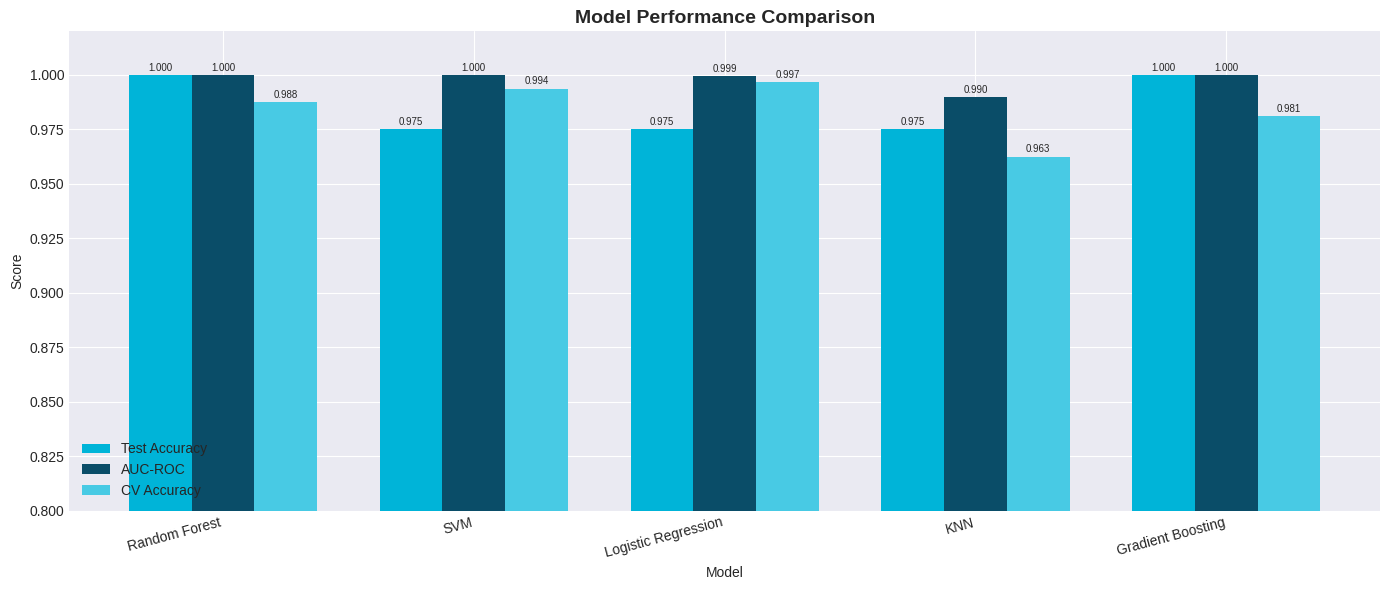

In [ ]:
# Step 7.1 — Model Comparison Chart
model_names = list(results.keys())
accuracies  = [results[m]['Accuracy'] for m in model_names]
aucs        = [results[m]['AUC-ROC'] for m in model_names]
cvs         = [results[m]['CV Accuracy'] for m in model_names]

x = np.arange(len(model_names))
width = 0.25

fig, ax = plt.subplots(figsize=(14, 6))
bars1 = ax.bar(x - width, accuracies, width, label='Test Accuracy', color='#00b4d8')
bars2 = ax.bar(x,          aucs,       width, label='AUC-ROC',       color='#0a4d68')
bars3 = ax.bar(x + width,  cvs,        width, label='CV Accuracy',   color='#48cae4')

ax.set_xlabel('Model')
ax.set_ylabel('Score')
ax.set_title('Model Performance Comparison', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(model_names, rotation=15, ha='right')
ax.set_ylim(0.8, 1.02)
ax.legend()

for bar in [*bars1, *bars2, *bars3]:
    ax.annotate(f'{bar.get_height():.3f}',
                xy=(bar.get_x() + bar.get_width()/2, bar.get_height()),
                xytext=(0,3), textcoords='offset points', ha='center', fontsize=7)

plt.tight_layout()
plt.show()

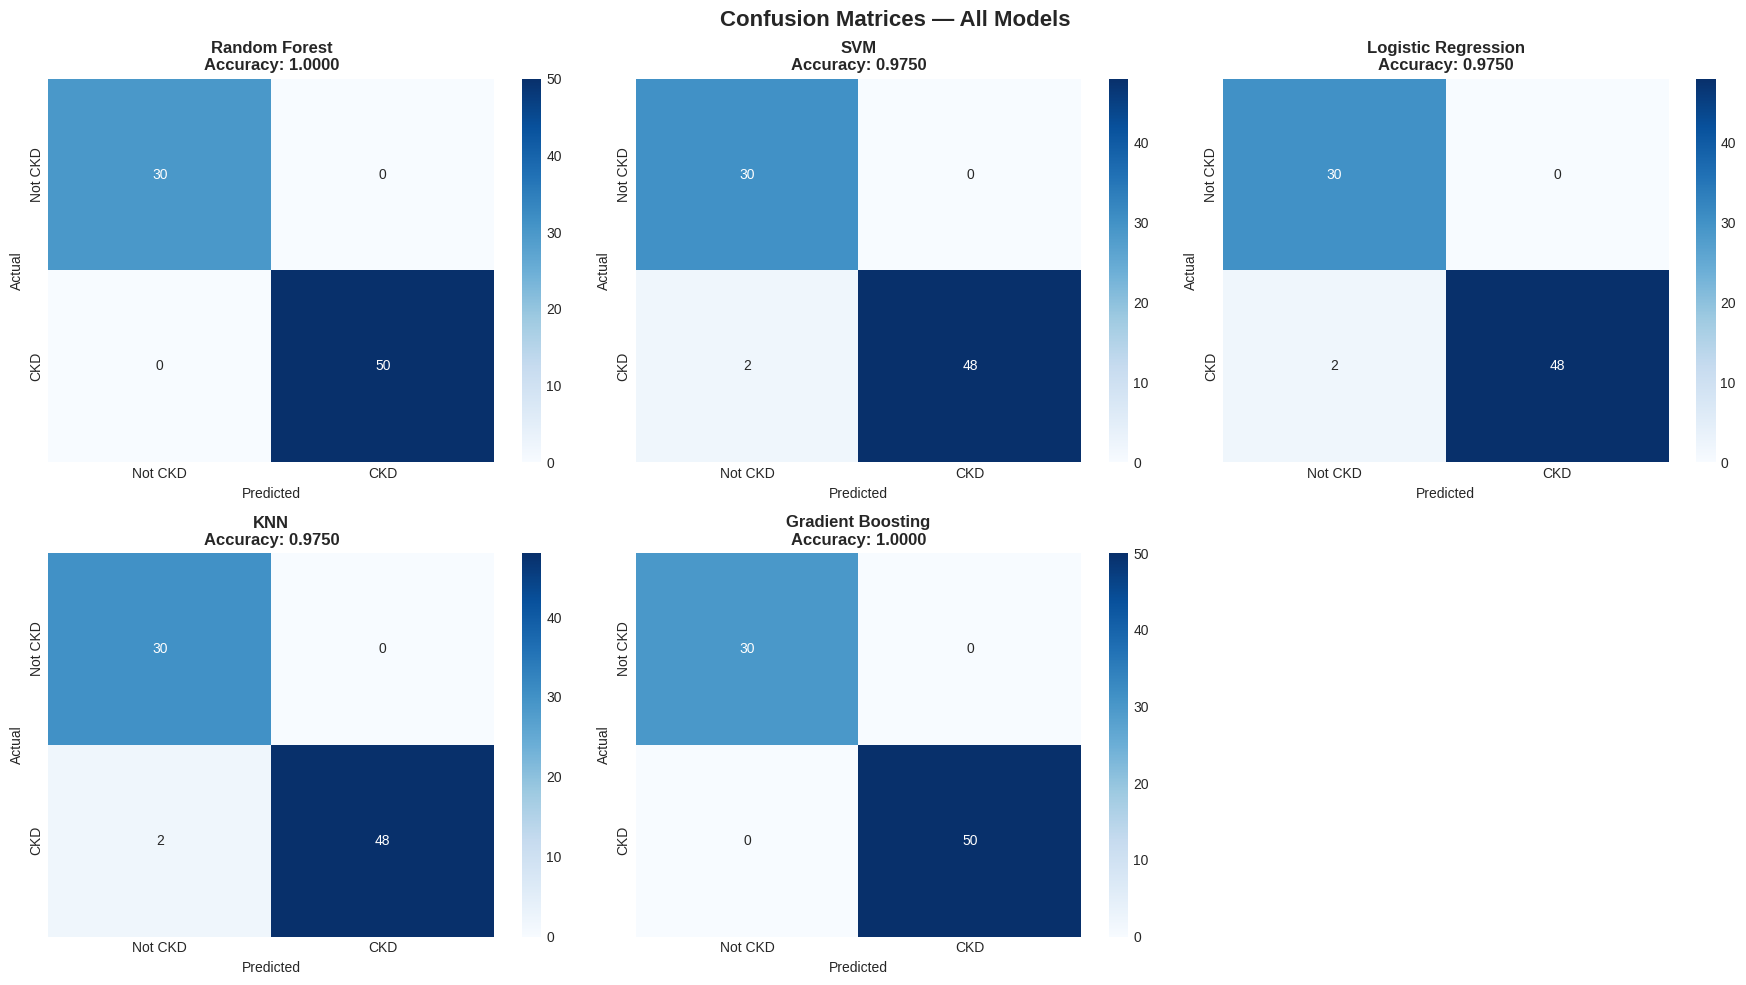

In [ ]:
# Step 7.2 — Confusion Matrices for all models
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, (name, res) in enumerate(results.items()):
    cm = confusion_matrix(y_test, res['y_pred'])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i],
                xticklabels=['Not CKD','CKD'],
                yticklabels=['Not CKD','CKD'])
    axes[i].set_title(f'{name}\nAccuracy: {res["Accuracy"]:.4f}', fontweight='bold')
    axes[i].set_ylabel('Actual')
    axes[i].set_xlabel('Predicted')

axes[-1].set_visible(False)
plt.suptitle('Confusion Matrices — All Models', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

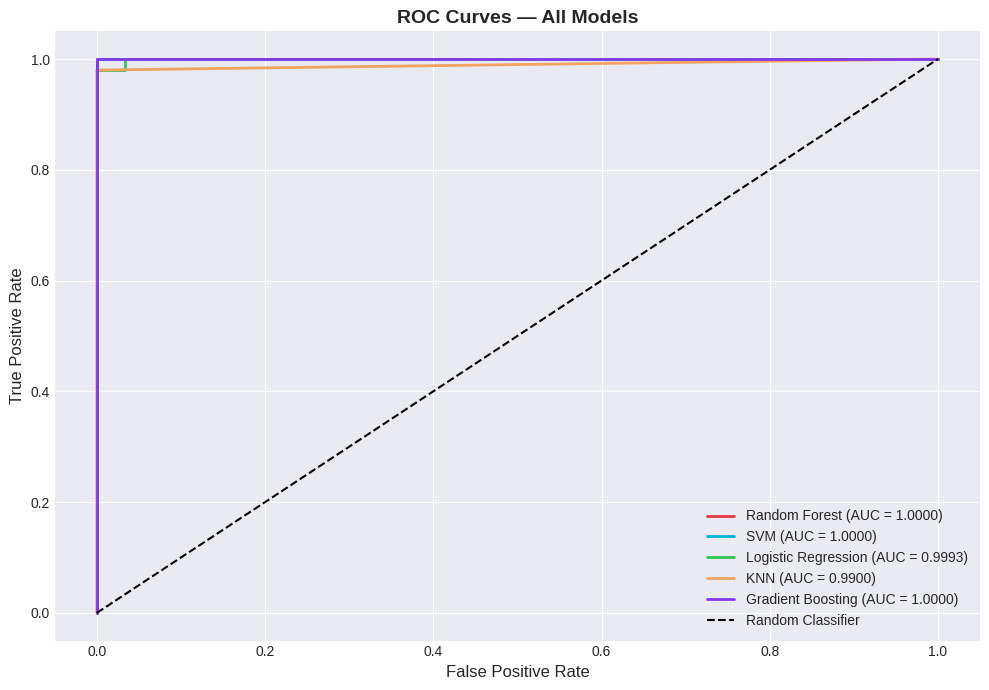

In [ ]:
# Step 7.3 — ROC Curves
plt.figure(figsize=(10, 7))
colors = ['#e63946','#00b4d8','#2dc653','#f4a261','#8338ec']

for (name, res), color in zip(results.items(), colors):
    fpr, tpr, _ = roc_curve(y_test, res['y_prob'])
    plt.plot(fpr, tpr, label=f"{name} (AUC = {res['AUC-ROC']:.4f})", color=color, lw=2)

plt.plot([0,1],[0,1],'k--', lw=1.5, label='Random Classifier')
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('ROC Curves — All Models', fontsize=14, fontweight='bold')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

In [ ]:
# Step 7.4 — Select best model and show classification report
best_name = max(results, key=lambda m: results[m]['Accuracy'])
best_model = results[best_name]['model']
best_pred  = results[best_name]['y_pred']

print(f'🏆 Best Model: {best_name}')
print(f'   Accuracy : {results[best_name]['Accuracy']:.4f}')
print(f'   AUC-ROC  : {results[best_name]['AUC-ROC']:.4f}')
print()
print('📋 Classification Report:')
print(classification_report(y_test, best_pred, target_names=['Not CKD','CKD']))

🏆 Best Model: Random Forest
   Accuracy : 1.0000
   AUC-ROC  : 1.0000

📋 Classification Report:
              precision    recall  f1-score   support

     Not CKD       1.00      1.00      1.00        30
         CKD       1.00      1.00      1.00        50

    accuracy                           1.00        80
   macro avg       1.00      1.00      1.00        80
weighted avg       1.00      1.00      1.00        80



## 💾 Step 8 — Save Model & Scaler

In [ ]:
import joblib

# Save the best model and scaler for use in Flask app
joblib.dump(best_model, 'ckd_model.pkl')
joblib.dump(scaler, 'ckd_scaler.pkl')
joblib.dump(feature_cols, 'ckd_features.pkl')

print(f'✅ Model saved as: ckd_model.pkl')
print(f'✅ Scaler saved as: ckd_scaler.pkl')
print(f'✅ Feature list saved as: ckd_features.pkl')
print(f'\n🏆 Best model ({best_name}) is ready for deployment!')

✅ Model saved as: ckd_model.pkl
✅ Scaler saved as: ckd_scaler.pkl
✅ Feature list saved as: ckd_features.pkl

🏆 Best model (Random Forest) is ready for deployment!


## 🔮 Step 9 — Symptom-to-Clinical Value Mapping

Since our frontend users are **general public** (no lab tests), we map their symptom answers to approximate clinical values for the model.

In [ ]:
# Symptom-to-Clinical Mapping Logic
# This is used by the Flask backend to convert user answers to model input

def symptom_to_clinical(user_input):
    """
    Maps general public symptom answers to approximate clinical values.
    user_input: dict with keys from the symptom form
    Returns: dict with clinical feature values for the ML model
    """
    age   = float(user_input.get('age', 40))
    htn   = 1 if user_input.get('hypertension') == 'yes' else 0
    dm    = 1 if user_input.get('diabetes') == 'yes' else 0
    smoke = user_input.get('smoke_alcohol') == 'yes'
    tired = user_input.get('fatigue') == 'yes'
    swell = user_input.get('swelling') == 'yes'
    nause = user_input.get('poor_appetite') == 'yes'
    urine = user_input.get('urination', 'normal')
    pain  = user_input.get('back_pain') == 'yes'
    famhx = user_input.get('family_history') == 'yes'
    obese = user_input.get('obesity') == 'yes'

    # Approximate clinical values based on symptoms
    # Blood Pressure
    bp = 90 if htn else 70
    if smoke: bp += 10

    # Specific Gravity — lower if kidney issues
    sg = 1.010 if (tired or swell or urine != 'normal') else 1.020

    # Albumin — elevated if symptoms suggest protein leak
    al = 2 if (swell or urine == 'less') else 0

    # Sugar
    su = 2 if dm else 0

    # RBC, PC (0=normal, 1=abnormal)
    rbc = 1 if (tired or pain) else 0
    pc  = 1 if pain else 0
    pcc = 1 if pain else 0
    ba  = 1 if pain else 0

    # Blood Glucose Random
    bgr = 180 if dm else 110
    if obese: bgr += 30

    # Blood Urea
    bu = 60 if (tired and swell) else 30
    if famhx: bu += 15

    # Serum Creatinine
    sc = 2.5 if (tired and swell and urine == 'less') else 1.0
    if age > 60: sc += 0.5

    # Sodium
    sod = 130 if swell else 140

    # Potassium
    pot = 5.5 if (urine == 'less' and tired) else 4.5

    # Hemoglobin
    hemo = 10.5 if tired else 14.0
    if famhx: hemo -= 1.0

    # Packed Cell Volume
    pcv = 32 if tired else 44

    # WBC, RBC count
    wbcc = 9000 if pain else 7500
    rbcc = 3.5 if tired else 5.0

    # Conditions
    cad    = 1 if (htn and age > 50) else 0
    appet  = 1 if nause else 0  # 1=poor
    pe     = 1 if swell else 0
    ane    = 1 if tired else 0

    clinical = {
        'age': age, 'bp': bp, 'sg': sg, 'al': al, 'su': su,
        'rbc': rbc, 'pc': pc, 'pcc': pcc, 'ba': ba,
        'bgr': bgr, 'bu': bu, 'sc': sc, 'sod': sod, 'pot': pot,
        'hemo': hemo, 'pcv': pcv, 'wbcc': wbcc, 'rbcc': rbcc,
        'htn': htn, 'dm': dm, 'cad': cad,
        'appet': appet, 'pe': pe, 'ane': ane
    }
    return clinical

# Test it
test_input = {
    'age': 55, 'hypertension': 'yes', 'diabetes': 'yes',
    'smoke_alcohol': 'no', 'fatigue': 'yes', 'swelling': 'yes',
    'poor_appetite': 'yes', 'urination': 'less', 'back_pain': 'no',
    'family_history': 'yes', 'obesity': 'no'
}
clinical_vals = symptom_to_clinical(test_input)
print('Test symptom input → Clinical values:')
for k, v in clinical_vals.items():
    print(f'  {k:8s}: {v}')

Test symptom input → Clinical values:
  age     : 55.0
  bp      : 90
  sg      : 1.01
  al      : 2
  su      : 2
  rbc     : 1
  pc      : 0
  pcc     : 0
  ba      : 0
  bgr     : 180
  bu      : 75
  sc      : 2.5
  sod     : 130
  pot     : 5.5
  hemo    : 9.5
  pcv     : 32
  wbcc    : 7500
  rbcc    : 3.5
  htn     : 1
  dm      : 1
  cad     : 1
  appet   : 1
  pe      : 1
  ane     : 1


In [ ]:
from google.colab import files

files.download('ckd_model.pkl')
files.download('ckd_scaler.pkl')
files.download('ckd_features.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>